# 02 · Exploratory Data Analysis

**Input:** the cleaned datasets produced by `01_preprocessing`.

**Questions this EDA answers**
1. What does the corpus look like, and how big and balanced is it?
2. Do the engineered structural features separate the page types, i.e. are they worth using?
3. Does the vocabulary separate page types? Do pages cluster by *type*, or by *company*?
4. How do the extracted KPIs behave: scale, skew, missingness, correlations, year-on-year change?
5. Do the reported numbers follow **Benford's law**, a standard forensic-accounting check?

Each section ends with an **insight** computed from the data.
The results are also exported to `ml/reports/eda.json`, which the app's *Model Lab → EDA* tab renders.

In [1]:
import json
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE
from wordcloud import WordCloud

from ml.paths import PROCESSED_DIR, REPORTS_DIR, FIGURES_DIR
from ml.preprocess.label_pages import LABELS

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.width", 160)
SEED = 42
EDA = {}  # collected for the GUI


def save(name):
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"02_{name}.png", dpi=130)
    plt.show()


def insight(text):
    print("INSIGHT:", text)
    EDA.setdefault("insights", []).append(text)

In [2]:
pages = pd.read_json(PROCESSED_DIR / "pages_clean.jsonl", lines=True)
kpis = pd.read_csv(PROCESSED_DIR / "kpis_clean.csv")
pages["report"] = pages.company.str.split().str[0] + " " + pages.fiscal_year.astype(str)
order = [l for l in LABELS if l in set(pages.label)]
FEATURES = ["n_chars", "n_words", "n_lines", "n_numbers", "digit_ratio", "numeric_line_ratio",
            "avg_line_len", "has_rupee", "rel_position"]
print(pages.shape, kpis.shape)

(2199, 21) (125, 15)


## 1. Corpus overview

,report,sector,pages,words (k)
1,Adani 2025,Metals & Mining,609,286.6
4,Hindustan 2025,Capital Goods,411,166.3
2,Adani 2026,Metals & Mining,392,302.4
5,Hindustan 2026,Capital Goods,386,155.8
3,Bharti 2026,Telecommunication,301,252.8
0,ADARSH 2026,Unknown,100,34.5


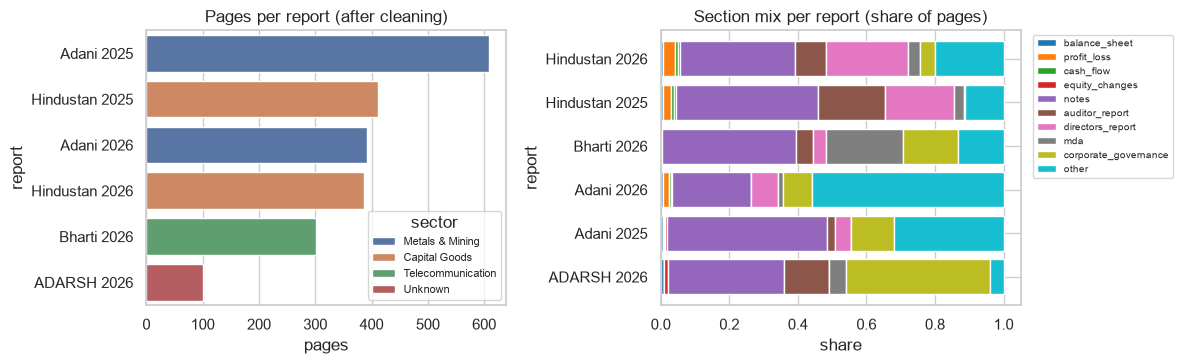

INSIGHT: 2,199 cleaned pages from 6 reports of 4 companies (1.20 M words). Report length ranges from 100 to 609 pages, so per-report section shares vary a lot.


In [3]:
corpus = (pages.groupby(["report", "sector"])
               .agg(pages=("page_number", "size"), words=("n_words", "sum"))
               .reset_index().sort_values("pages", ascending=False))
corpus["words (k)"] = (corpus.words / 1000).round(1)
display(corpus.drop(columns="words"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.barplot(data=corpus, y="report", x="pages", hue="sector", dodge=False, ax=axes[0])
axes[0].set_title("Pages per report (after cleaning)")
axes[0].legend(fontsize=8, title="sector")
mix = pd.crosstab(pages.report, pages.label, normalize="index")[order]
mix.plot.barh(stacked=True, ax=axes[1], colormap="tab10", width=.8, legend=False)
axes[1].set_title("Section mix per report (share of pages)")
axes[1].set_xlabel("share")
axes[1].legend(bbox_to_anchor=(1.02, 1), fontsize=7)
save("corpus_overview")

EDA["corpus"] = corpus.drop(columns="words").to_dict("records")
insight(f"{len(pages):,} cleaned pages from {pages.report_id.nunique()} reports of {pages.company.nunique()} companies "
        f"({pages.n_words.sum() / 1e6:.2f} M words). Report length ranges from {corpus.pages.min()} to "
        f"{corpus.pages.max()} pages, so per-report section shares vary a lot.")

## 2. Target variable: page-type distribution

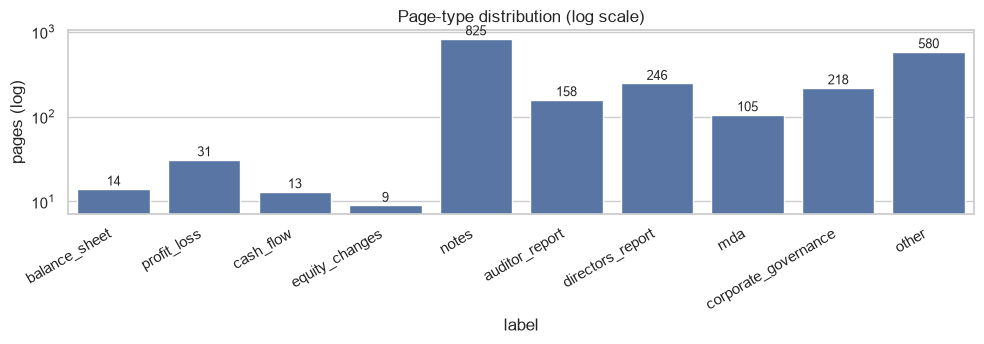

INSIGHT: Severe imbalance: the largest class ('notes', 825) is 92× the smallest ('equity_changes', 9). Primary statements (BS/P&L/CF/SoCE) are only 3.0% of pages, yet they hold the headline KPIs. So we use macro-F1 plus class weights, not accuracy.


In [4]:
counts = pages.label.value_counts().reindex(order)
fig, ax = plt.subplots(figsize=(10, 3.6))
sns.barplot(x=counts.index, y=counts.values, ax=ax, color=sns.color_palette()[0])
ax.set_yscale("log")
ax.set_title("Page-type distribution (log scale)")
ax.set_ylabel("pages (log)")
plt.xticks(rotation=30, ha="right")
for i, v in enumerate(counts.values):
    ax.text(i, v * 1.1, str(v), ha="center", fontsize=9)
save("class_distribution")

EDA["class_counts"] = counts.to_dict()
statement_share = counts.reindex(["balance_sheet", "profit_loss", "cash_flow", "equity_changes"]).sum() / counts.sum()
insight(f"Severe imbalance: the largest class ('{counts.idxmax()}', {counts.max()}) is "
        f"{counts.max() / counts.min():.0f}× the smallest ('{counts.idxmin()}', {counts.min()}). Primary statements "
        f"(BS/P&L/CF/SoCE) are only {statement_share:.1%} of pages, yet they hold the headline KPIs. So we use "
        f"macro-F1 plus class weights, not accuracy.")

## 3. Univariate analysis of the structural features

In [5]:
desc = pages[FEATURES].describe().T
desc["skew"] = pages[FEATURES].skew()
desc["kurtosis"] = pages[FEATURES].kurtosis()
desc.round(3)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
n_chars,2199.0,3563.557,2027.414,52.000,2030.000,3214.000,4579.500,11687.000,1.073,1.111
n_words,2199.0,545.003,301.565,7.000,318.500,490.000,705.000,1764.000,1.113,1.329
n_lines,2199.0,134.915,100.490,1.000,76.000,111.000,165.000,1055.000,3.332,19.315
n_numbers,2199.0,58.351,66.371,0.000,17.000,42.000,78.000,821.000,4.191,31.058
digit_ratio,2199.0,0.069,0.078,0.000,0.013,0.034,0.104,0.792,1.973,7.708
numeric_line_ratio,2199.0,0.162,0.193,0.000,0.008,0.059,0.295,0.964,1.061,0.081
avg_line_len,2199.0,31.831,19.916,4.190,16.620,27.620,41.240,106.690,1.226,1.444
has_rupee,2199.0,0.462,0.499,0.000,0.000,0.000,1.000,1.000,0.154,-1.978
rel_position,2199.0,0.504,0.287,0.002,0.258,0.505,0.748,1.000,-0.004,-1.193


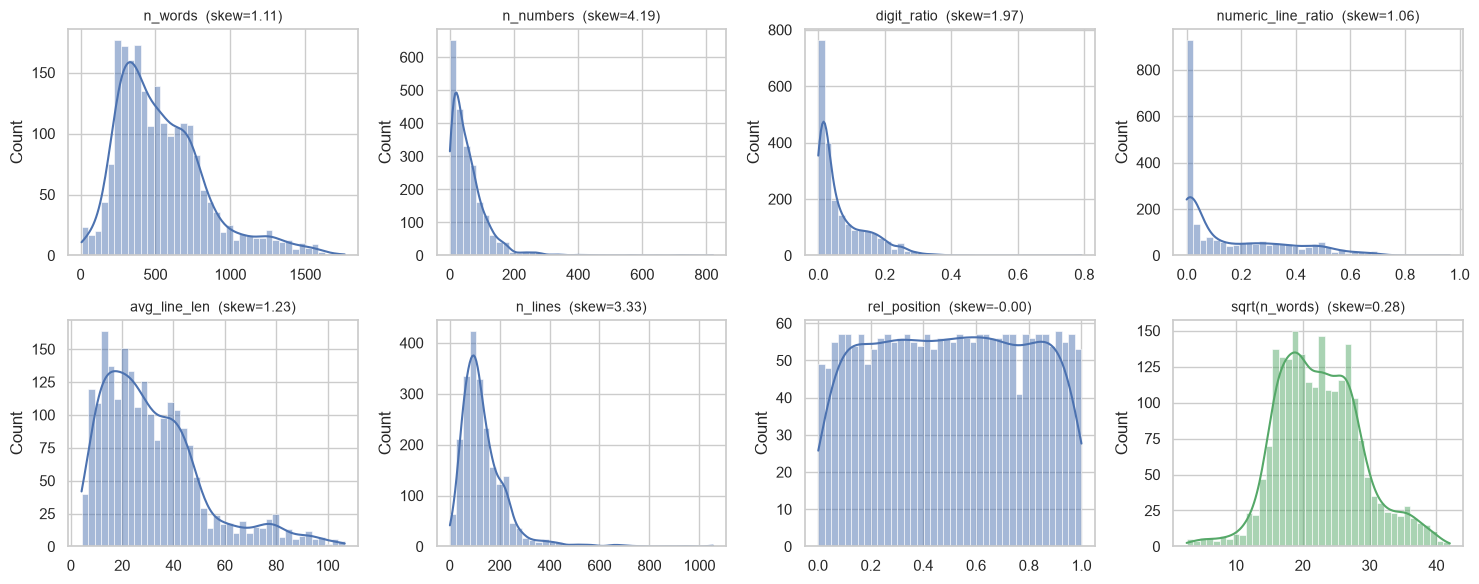

INSIGHT: Count features are right-skewed (n_words skew 1.11, n_numbers skew 4.19). log1p over-corrects n_words to -1.34 because of short divider pages; sqrt gives the most symmetric shape (0.28). Scale-sensitive models (LogReg/SVM) get power-transformed + standardised inputs (Yeo-Johnson in the pipeline); tree models need no transformation.


In [6]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, f in zip(axes.flat, ["n_words", "n_numbers", "digit_ratio", "numeric_line_ratio",
                             "avg_line_len", "n_lines", "rel_position"]):
    sns.histplot(pages[f], bins=40, kde=True, ax=ax)
    ax.set_title(f"{f}  (skew={pages[f].skew():.2f})", fontsize=10)
    ax.set_xlabel("")
transforms = {"none": pages.n_words, "sqrt": np.sqrt(pages.n_words), "log1p": np.log1p(pages.n_words)}
skews = {k: v.skew() for k, v in transforms.items()}
best_t = min(skews, key=lambda k: abs(skews[k]))
sns.histplot(transforms[best_t], bins=40, kde=True, ax=axes.flat[-1], color="C2")
axes.flat[-1].set_title(f"{best_t}(n_words)  (skew={skews[best_t]:.2f})", fontsize=10)
axes.flat[-1].set_xlabel("")
save("feature_histograms")
pd.Series(skews, name="skew of n_words").round(2).to_frame().T

EDA["feature_hist"] = {
    f: dict(zip(["counts", "edges"], [h.tolist(), e.round(4).tolist()]))
    for f in ["n_words", "digit_ratio", "numeric_line_ratio"]
    for h, e in [np.histogram(pages[f], bins=30)]
}
insight(f"Count features are right-skewed (n_words skew {skews['none']:.2f}, n_numbers skew {pages.n_numbers.skew():.2f}). "
        f"log1p over-corrects n_words to {skews['log1p']:.2f} because of short divider pages; {best_t} gives the most symmetric "
        f"shape ({skews[best_t]:.2f}). Scale-sensitive models (LogReg/SVM) get power-transformed + standardised inputs "
        f"(Yeo-Johnson in the pipeline); tree models need no transformation.")

## 4. Bivariate analysis: features vs page type

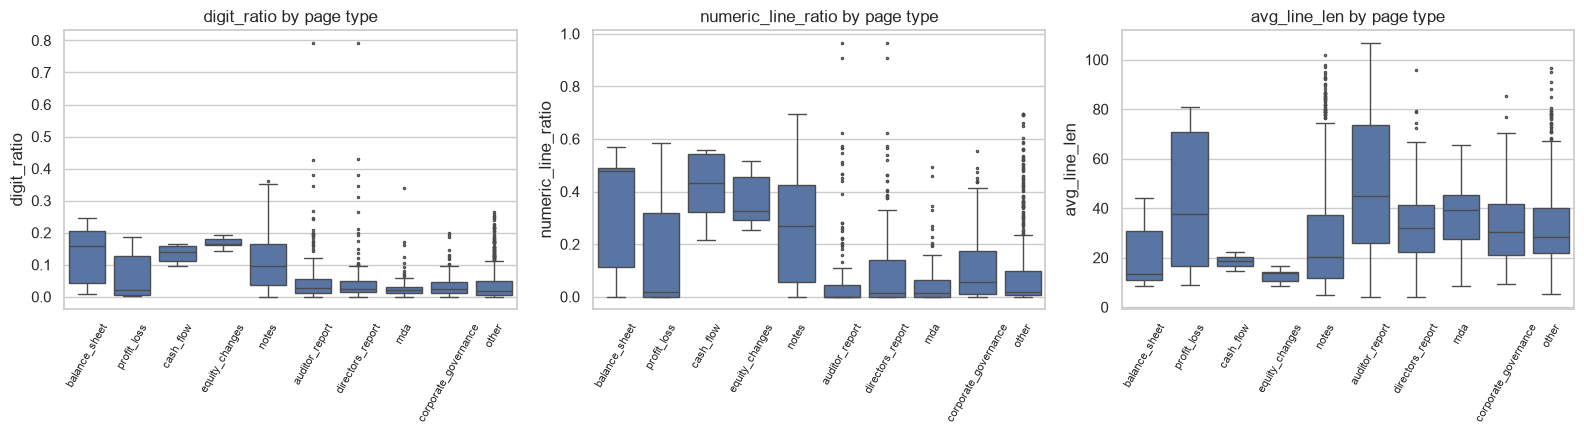

,digit_ratio,numeric_line_ratio,avg_line_len,n_words
label,,,,
balance_sheet,0.159,0.478,13.585,370.5
profit_loss,0.021,0.019,37.840,569.0
cash_flow,0.139,0.434,18.660,320.0
equity_changes,0.166,0.328,13.650,370.0
notes,0.097,0.271,20.180,443.0
auditor_report,0.026,0.000,44.910,567.5
directors_report,0.025,0.014,31.790,421.0
mda,0.020,0.014,39.150,686.0
corporate_governance,0.023,0.057,30.360,483.0


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, f in zip(axes, ["digit_ratio", "numeric_line_ratio", "avg_line_len"]):
    sns.boxplot(data=pages, x="label", y=f, order=order, ax=ax, fliersize=1.5)
    ax.set_title(f"{f} by page type")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=60, labelsize=8)
save("features_by_label")

by_label = pages.groupby("label")[["digit_ratio", "numeric_line_ratio", "avg_line_len", "n_words"]].median().reindex(order)
EDA["feature_medians_by_label"] = by_label.round(4).to_dict("index")
by_label.round(3)

**Statistical test.** Are the feature distributions different across page types? The features are
non-normal (see §3), so we use the non-parametric **Kruskal–Wallis H-test** rather than ANOVA. We report
the effect size ε² = (H − k + 1) / (n − k).

In [8]:
rows = []
k, n = len(order), len(pages)
for f in FEATURES:
    h, p = stats.kruskal(*[pages.loc[pages.label == l, f] for l in order])
    rows.append({"feature": f, "H": round(h, 1), "p_value": p, "epsilon²": round((h - k + 1) / (n - k), 3)})
kw = pd.DataFrame(rows).sort_values("H", ascending=False)
EDA["kruskal"] = kw.assign(p_value=kw.p_value.map(lambda v: float(f"{v:.3g}"))).to_dict("records")
kw.style.format({"p_value": "{:.2e}"})

,feature,H,p_value,epsilon²
8,rel_position,1023.400000,1.53e-214,0.463000
4,digit_ratio,478.300000,2.57e-97,0.214000
5,numeric_line_ratio,447.100000,1.17e-90,0.200000
7,has_rupee,395.500000,1.23e-79,0.177000
3,n_numbers,360.600000,3.39e-72,0.161000
6,avg_line_len,235.700000,1.03e-45,0.104000
2,n_lines,108.100000,3.50e-19,0.045000
0,n_chars,100.200000,1.42e-17,0.042000
1,n_words,54.800000,1.31e-08,0.021000


In [9]:
top = kw.iloc[0]
insight(f"All features differ significantly across page types (Kruskal-Wallis p < 0.001). '{top.feature}' "
        f"separates best (ε²={top['epsilon²']}). Statement pages have a median digit_ratio of "
        f"{by_label.loc[['balance_sheet', 'profit_loss', 'cash_flow'], 'digit_ratio'].median():.2f} vs "
        f"{by_label.loc[['mda', 'directors_report'], 'digit_ratio'].median():.2f} for narrative sections. "
        f"The engineered features are informative.")

INSIGHT: All features differ significantly across page types (Kruskal-Wallis p < 0.001). 'rel_position' separates best (ε²=0.463). Statement pages have a median digit_ratio of 0.14 vs 0.02 for narrative sections. The engineered features are informative.


### Where does each section sit in a report?

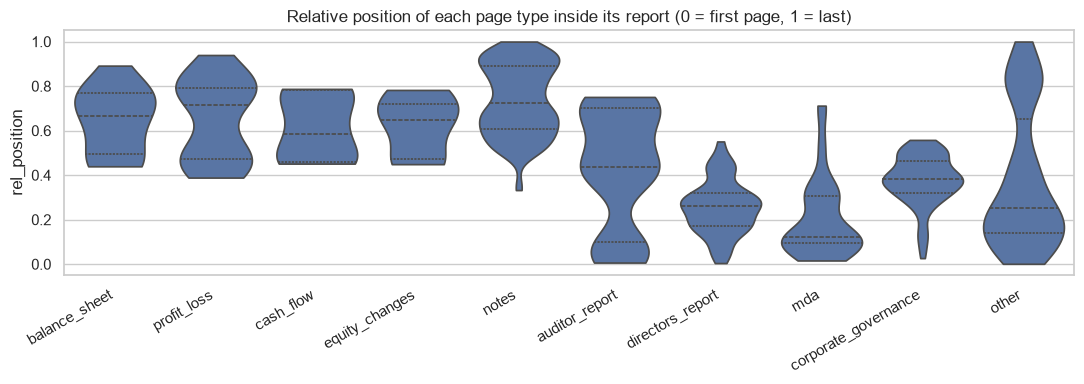

INSIGHT: Reports follow a common order: narrative (MD&A median position 0.12, Directors' report 0.26) comes before the financial statements (balance sheet 0.67, notes 0.73). rel_position is a useful prior for the classifier.


In [10]:
fig, ax = plt.subplots(figsize=(11, 4))
sns.violinplot(data=pages, x="label", y="rel_position", order=order, cut=0, inner="quartile", ax=ax, density_norm="width")
ax.set_title("Relative position of each page type inside its report (0 = first page, 1 = last)")
ax.set_xlabel("")
plt.xticks(rotation=30, ha="right")
save("position_by_label")

pos = pages.groupby("label").rel_position.median().reindex(order)
EDA["position_median"] = pos.round(3).to_dict()
insight(f"Reports follow a common order: narrative (MD&A median position {pos['mda']:.2f}, Directors' report "
        f"{pos['directors_report']:.2f}) comes before the financial statements (balance sheet {pos.get('balance_sheet', np.nan):.2f}, "
        f"notes {pos['notes']:.2f}). rel_position is a useful prior for the classifier.")

### Feature correlations

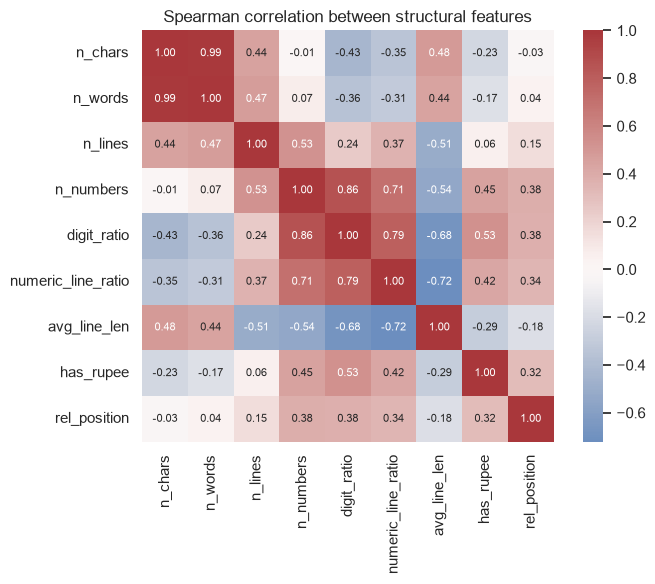

INSIGHT: Strongest redundancy: n_chars ~ n_words (ρ=0.99) and n_numbers ~ digit_ratio (ρ=0.86). Linear models get one feature from each highly-correlated pair (or L2 regularisation); trees are unaffected.


In [11]:
corr = pages[FEATURES].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True, ax=ax, annot_kws={"size": 8})
ax.set_title("Spearman correlation between structural features")
save("feature_correlation")

EDA["feature_corr"] = {"labels": FEATURES, "matrix": corr.round(3).values.tolist()}
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().sort_values(key=abs, ascending=False)
insight(f"Strongest redundancy: {pairs.index[0][0]} ~ {pairs.index[0][1]} (ρ={pairs.iloc[0]:.2f}) and "
        f"{pairs.index[1][0]} ~ {pairs.index[1][1]} (ρ={pairs.iloc[1]:.2f}). Linear models get one feature from each "
        f"highly-correlated pair (or L2 regularisation); trees are unaffected.")

**Chi-square test of independence:** is the statement *scope* (standalone / consolidated) related to page type?

In [12]:
ct = pd.crosstab(pages.label, pages.scope).reindex(order)
chi2, p, dof, _ = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
display(ct)
insight(f"Scope vs page type: χ²={chi2:.0f}, dof={dof}, p={p:.1e}, Cramér's V={cramers_v:.2f}. "
        f"'consolidated'/'standalone' mostly appears on statement and notes pages, so scope is mainly informative for those pages.")
EDA["scope_chi2"] = {"chi2": round(chi2, 1), "dof": int(dof), "p": float(f"{p:.3g}"), "cramers_v": round(cramers_v, 3)}

scope,consolidated,standalone,unknown
label,,,
balance_sheet,8,4,2
profit_loss,9,5,17
cash_flow,5,4,4
equity_changes,5,2,2
notes,291,226,308
auditor_report,22,14,122
directors_report,3,1,242
mda,8,2,95
corporate_governance,5,2,211


INSIGHT: Scope vs page type: χ²=866, dof=18, p=2.5e-172, Cramér's V=0.44. 'consolidated'/'standalone' mostly appears on statement and notes pages, so scope is mainly informative for those pages.


## 5. Text analysis
### 5.1 Most distinctive terms per page type (mean TF-IDF)

TF-IDF matrix: (2199, 8000) sparsity=0.9758


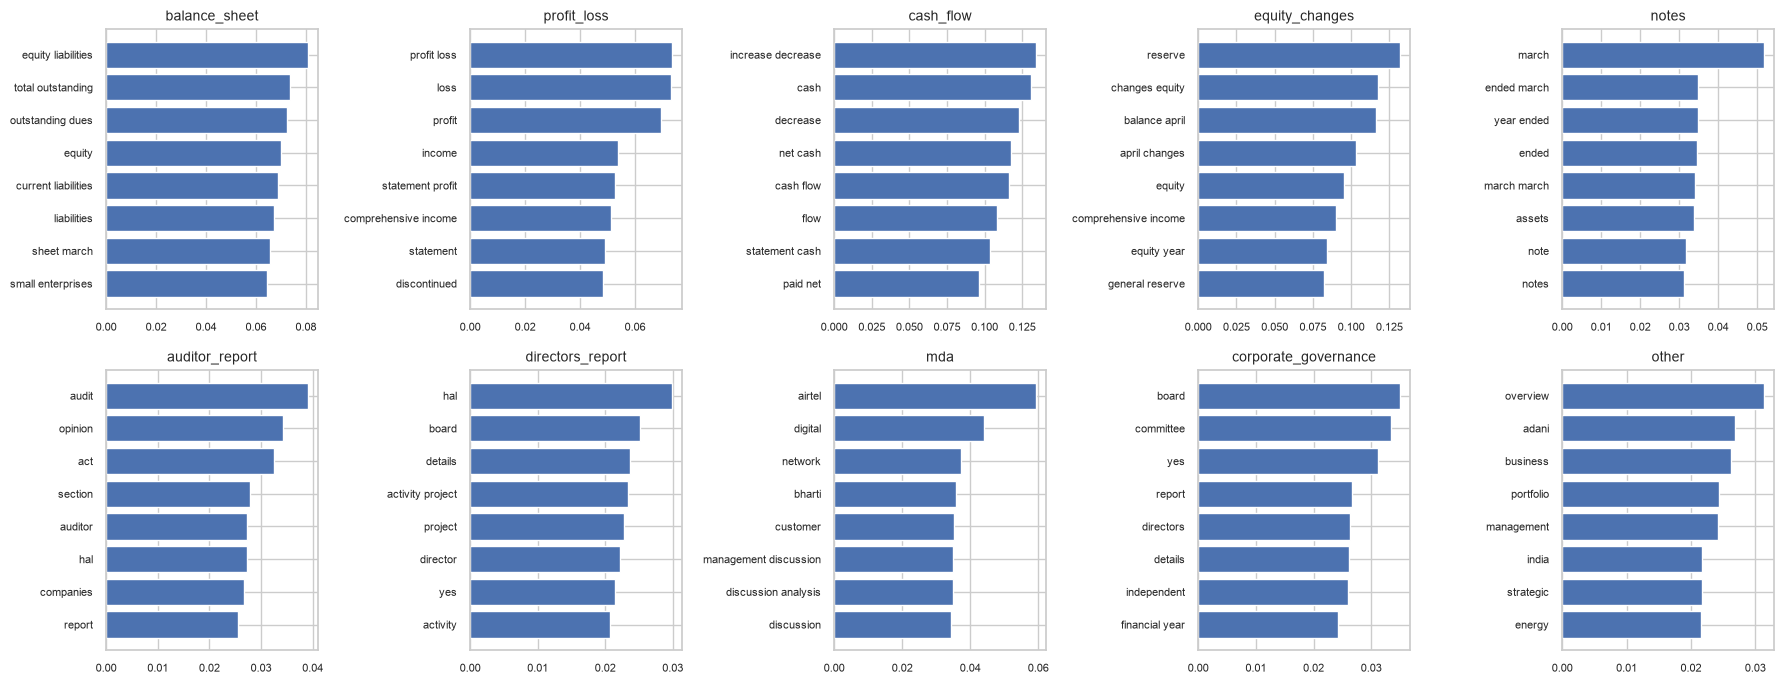

In [13]:
tfidf = TfidfVectorizer(max_features=8000, ngram_range=(1, 2), min_df=3, max_df=0.6, sublinear_tf=True,
                        stop_words="english", token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]{2,}\b")
X = tfidf.fit_transform(pages.clean_text)
terms = np.array(tfidf.get_feature_names_out())
print("TF-IDF matrix:", X.shape, f"sparsity={1 - X.nnz / np.prod(X.shape):.4f}")

top_terms = {}
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, label in zip(axes.flat, order):
    mean = np.asarray(X[(pages.label == label).values].mean(axis=0)).ravel()
    idx = mean.argsort()[::-1][:8]
    top_terms[label] = [[terms[i], round(float(mean[i]), 4)] for i in idx]
    ax.barh(terms[idx][::-1], mean[idx][::-1], color="C0")
    ax.set_title(label, fontsize=10)
    ax.tick_params(labelsize=8)
for ax in axes.flat[len(order):]:
    ax.axis("off")
save("top_terms")
EDA["top_terms"] = top_terms

### 5.2 Word clouds

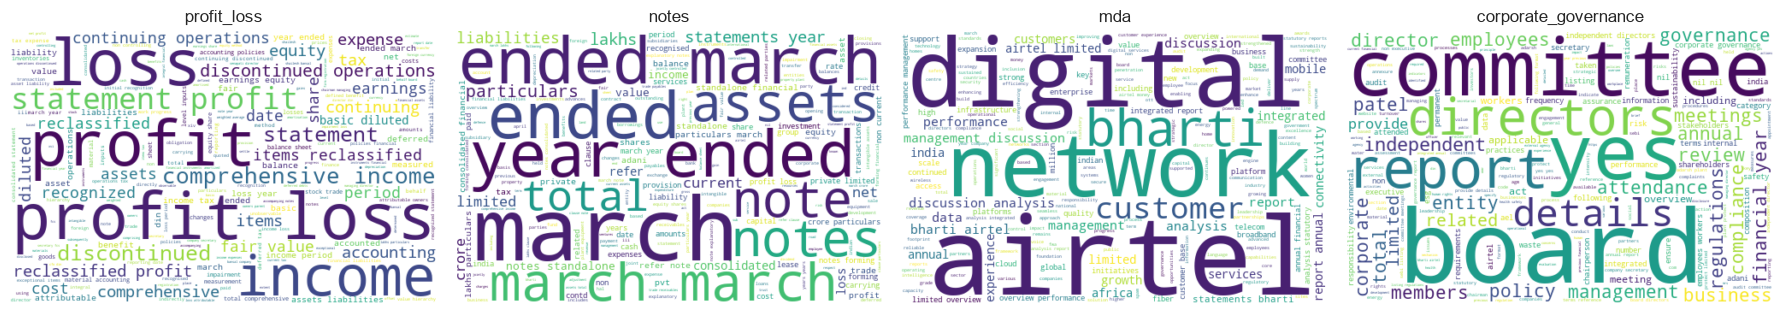

INSIGHT: Each page type has its own vocabulary, e.g. P&L: profit loss, loss, profit, income; MD&A: airtel, digital, network, bharti. Bag-of-words / TF-IDF should be a strong baseline representation.


In [14]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, label in zip(axes, ["profit_loss", "notes", "mda", "corporate_governance"]):
    mean = np.asarray(X[(pages.label == label).values].mean(axis=0)).ravel()
    wc = WordCloud(width=500, height=320, background_color="white", colormap="viridis", random_state=SEED)
    ax.imshow(wc.generate_from_frequencies(dict(zip(terms, mean))), interpolation="bilinear")
    ax.set_title(label)
    ax.axis("off")
save("wordclouds")

insight("Each page type has its own vocabulary, e.g. P&L: " + ", ".join(t for t, _ in top_terms["profit_loss"][:4])
        + "; MD&A: " + ", ".join(t for t, _ in top_terms["mda"][:4])
        + ". Bag-of-words / TF-IDF should be a strong baseline representation.")

### 5.3 Do pages cluster by type, or by company?
TF-IDF (8k dims) → **Truncated SVD (LSA, 50 dims)** → **t-SNE (2 dims)**.

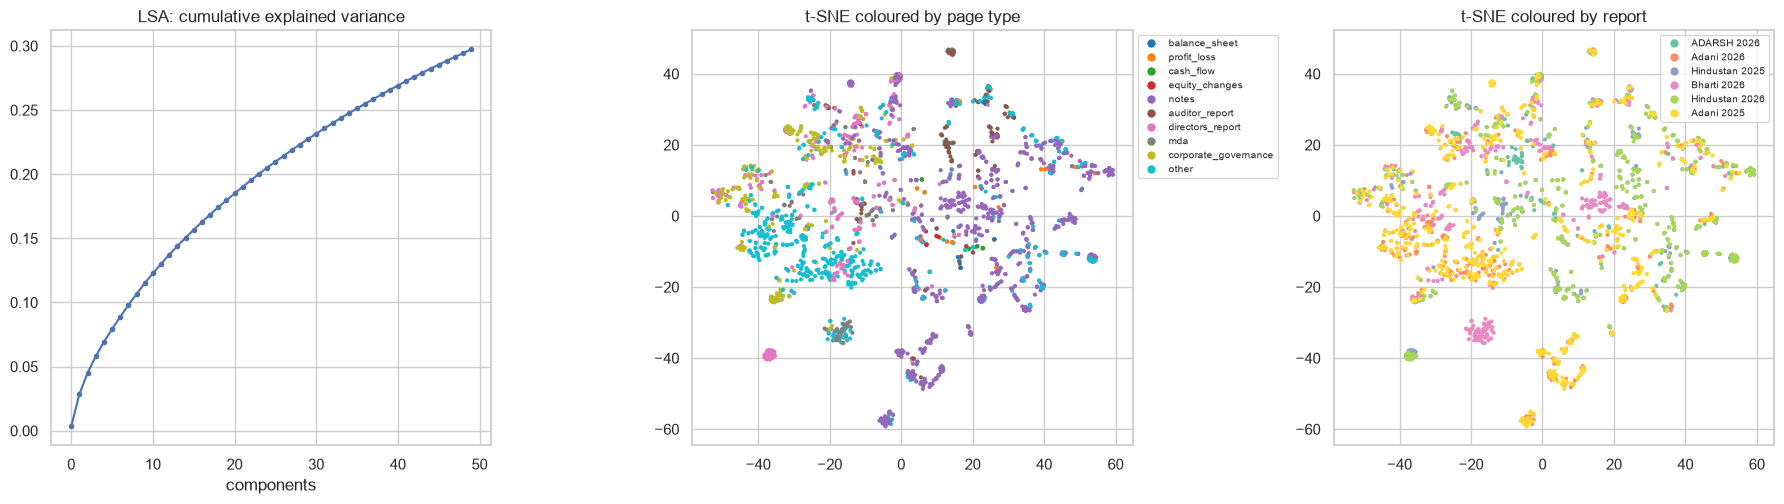

INSIGHT: LSA keeps 30% of TF-IDF variance in 50 dims. Silhouettes are near zero (page type -0.035, company 0.041): the classes overlap in pure vocabulary space, so text alone is not enough and the structural features matter. Confounding: auditor_report (73% from one company), other (71% from one company), directors_report (71% from one company), profit_loss (71% from one company), mda (65% from one company), cash_flow (62% from one company), corporate_governance (50% from one company). For example, the top MD&A terms are company names, so a model could learn 'company' instead of 'section'. This is why the split and the CV are grouped by company, and why more reports are needed.


In [15]:
svd = TruncatedSVD(n_components=50, random_state=SEED)
Z = svd.fit_transform(X)
evr = svd.explained_variance_ratio_
emb = TSNE(n_components=2, perplexity=35, init="pca", random_state=SEED).fit_transform(Z)
pages["tsne_x"], pages["tsne_y"] = emb[:, 0], emb[:, 1]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
axes[0].plot(np.cumsum(evr), marker=".")
axes[0].set_title("LSA: cumulative explained variance")
axes[0].set_xlabel("components")
sns.scatterplot(data=pages, x="tsne_x", y="tsne_y", hue="label", hue_order=order, s=9, ax=axes[1], palette="tab10", linewidth=0)
axes[1].set_title("t-SNE coloured by page type")
axes[1].legend(fontsize=7, markerscale=2, bbox_to_anchor=(1, 1))
sns.scatterplot(data=pages, x="tsne_x", y="tsne_y", hue="report", s=9, ax=axes[2], palette="Set2", linewidth=0)
axes[2].set_title("t-SNE coloured by report")
axes[2].legend(fontsize=7, markerscale=2)
for ax in axes[1:]:
    ax.set_xlabel("")
    ax.set_ylabel("")
save("tsne")

# Quantify: silhouette of the 2-D embedding w.r.t. label vs company
from sklearn.metrics import silhouette_score
sil_label = silhouette_score(Z, pages.label, metric="cosine", sample_size=1500, random_state=SEED)
sil_company = silhouette_score(Z, pages.company, metric="cosine", sample_size=1500, random_state=SEED)
company_share = pd.crosstab(pages.label, pages.company, normalize="index").max(axis=1)
confounded = company_share[company_share > 0.5].sort_values(ascending=False)
insight(f"LSA keeps {evr.sum():.0%} of TF-IDF variance in 50 dims. Silhouettes are near zero (page type {sil_label:.3f}, "
        f"company {sil_company:.3f}): the classes overlap in pure vocabulary space, so text alone is not enough and the "
        f"structural features matter. Confounding: " + ", ".join(f"{l} ({v:.0%} from one company)" for l, v in confounded.items())
        + ". For example, the top MD&A terms are company names, so a model could learn 'company' instead of 'section'. "
        "This is why the split and the CV are grouped by company, and why more reports are needed.")
EDA["label_company_confound"] = confounded.round(3).to_dict()

sample = pages.sample(min(1200, len(pages)), random_state=SEED)
EDA["tsne"] = sample[["tsne_x", "tsne_y", "label", "report"]].round(3).to_dict("records")
EDA["silhouette"] = {"by_label": round(sil_label, 4), "by_company": round(sil_company, 4)}

## 6. KPI analysis
### 6.1 Scale and distribution of monetary KPIs

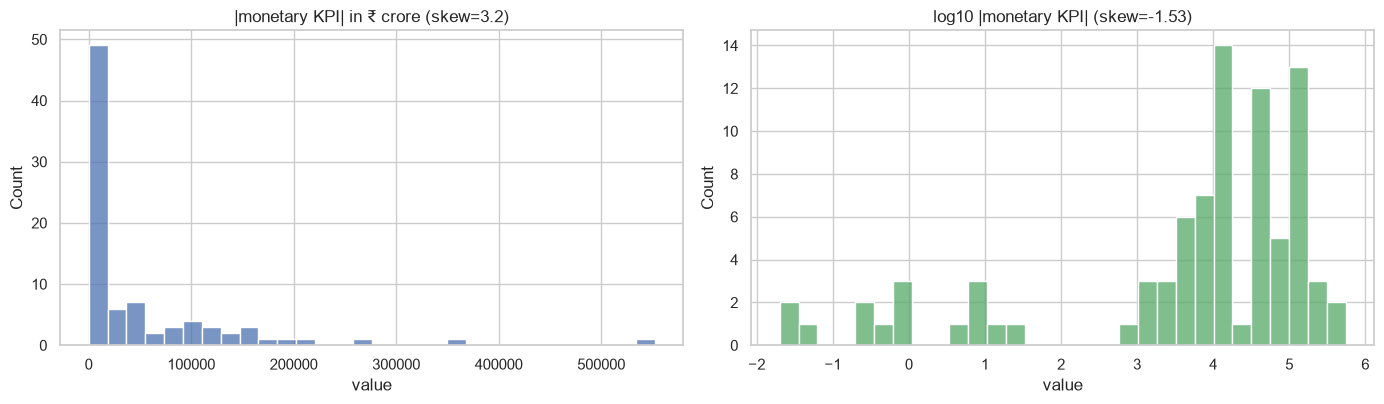

INSIGHT: Monetary KPIs span 7.4 orders of magnitude (₹0.02 cr to ₹552,152 cr). Raw values are extremely skewed (3.2); log10 is approximately symmetric, so KPI models and outlier rules work on log or ratio scale.


In [16]:
kp = kpis.dropna(subset=["value"]).copy()
kp["report"] = kp.company.str.split().str[0] + " " + kp.fiscal_year.astype(str)
money = kp[kp.unit == "₹ crore"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
sns.histplot(money.value.abs(), bins=30, ax=axes[0])
axes[0].set_title(f"|monetary KPI| in ₹ crore (skew={money.value.abs().skew():.1f})")
sns.histplot(np.log10(money.value.abs().clip(lower=0.01)), bins=30, ax=axes[1], color="C2")
axes[1].set_title(f"log10 |monetary KPI| (skew={np.log10(money.value.abs().clip(lower=0.01)).skew():.2f})")
save("kpi_distribution")

insight(f"Monetary KPIs span {np.log10(money.value.abs().max() / money.value.abs()[money.value.abs() > 0].min()):.1f} "
        f"orders of magnitude (₹{money.value.abs()[money.value.abs() > 0].min():.2f} cr to ₹{money.value.abs().max():,.0f} cr). "
        f"Raw values are extremely skewed ({money.value.abs().skew():.1f}); log10 is approximately symmetric, so KPI models and "
        f"outlier rules work on log or ratio scale.")

### 6.2 Headline KPIs across companies

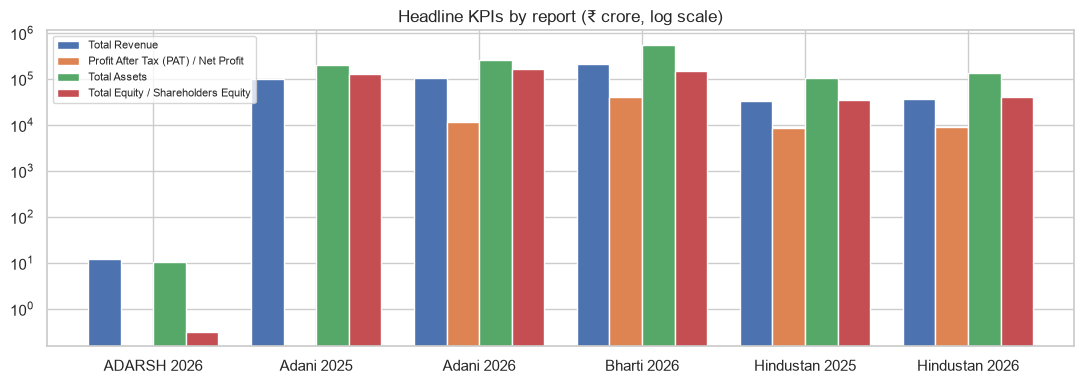

name,Total Revenue,Profit After Tax (PAT) / Net Profit,Total Assets,Total Equity / Shareholders Equity
report,,,,
ADARSH 2026,12.0,-0.0,10.3,0.3
Adani 2025,100365.1,NaN,198135.5,125706.8
Adani 2026,102943.2,11378.1,261600.4,163970.8
Bharti 2026,210972.8,40050.7,552151.6,149056.6
Hindustan 2025,33546.4,8384.9,106266.8,34985.2
Hindustan 2026,36793.5,9115.6,132414.6,41044.6


In [17]:
headline = ["Total Revenue", "Profit After Tax (PAT) / Net Profit", "Total Assets", "Total Equity / Shareholders Equity"]
hl = kp[kp.name.isin(headline)].pivot_table(index="report", columns="name", values="value")[headline]
fig, ax = plt.subplots(figsize=(11, 4))
hl.plot.bar(ax=ax, logy=True, width=.8)
ax.set_title("Headline KPIs by report (₹ crore, log scale)")
ax.set_xlabel("")
plt.xticks(rotation=0)
ax.legend(fontsize=8)
save("headline_kpis")
EDA["headline_kpis"] = hl.round(2).reset_index().to_dict("records")
hl.round(1)

### 6.3 Ratio analysis

In [18]:
ratios = pd.DataFrame({
    "net_margin_%": 100 * hl["Profit After Tax (PAT) / Net Profit"] / hl["Total Revenue"],
    "ROA_%": 100 * hl["Profit After Tax (PAT) / Net Profit"] / hl["Total Assets"],
    "ROE_%": 100 * hl["Profit After Tax (PAT) / Net Profit"] / hl["Total Equity / Shareholders Equity"],
    "equity_to_assets": hl["Total Equity / Shareholders Equity"] / hl["Total Assets"],
})
stored = kp[kp.unit == "x"].pivot_table(index="report", columns="name", values="value")
ratios = ratios.join(stored)
EDA["ratios"] = ratios.round(3).reset_index().to_dict("records")
display(ratios.round(2))

best_margin = ratios["net_margin_%"].idxmax()
insight(f"Computed ratios make companies of very different size comparable: {best_margin} has the highest net margin "
        f"({ratios['net_margin_%'].max():.1f}%). These scale-free ratios (margin, ROA, ROE, leverage, liquidity) are the "
        f"feature set for the financial-health classifier.")

,net_margin_%,ROA_%,ROE_%,equity_to_assets,Current Ratio,Debt-to-Equity Ratio,Interest Coverage Ratio
report,,,,,,,
ADARSH 2026,-0.17,-0.19,-6.45,0.03,1.53,3.35,0.95
Adani 2025,NaN,NaN,NaN,0.63,1.25,0.61,4.61
Adani 2026,11.05,4.35,6.94,0.63,1.35,0.53,2.80
Bharti 2026,18.98,7.25,26.87,0.27,1.72,1.01,5.00
Hindustan 2025,25.00,7.89,23.97,0.33,2.04,NaN,NaN
Hindustan 2026,24.78,6.88,22.21,0.31,2.61,NaN,NaN


INSIGHT: Computed ratios make companies of very different size comparable: Hindustan 2025 has the highest net margin (25.0%). These scale-free ratios (margin, ROA, ROE, leverage, liquidity) are the feature set for the financial-health classifier.


### 6.4 Year-on-year change (companies with two reports)

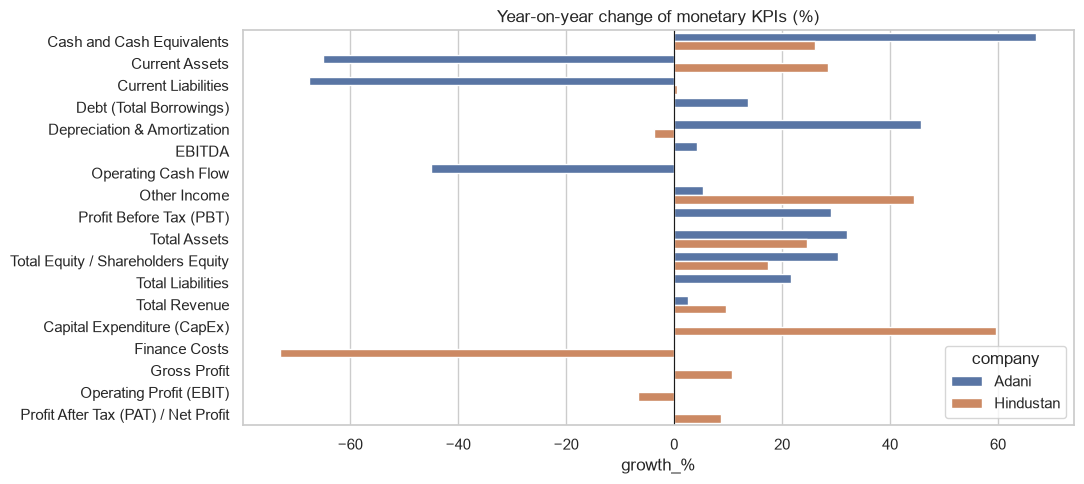

INSIGHT: Total-revenue growth: Adani +2.6%, Hindustan +9.7%. Large single-year swings in a KPI are the inputs the anomaly detector (z-score / Isolation Forest) scores.


In [19]:
yoy_rows = []
for company, g in kp[kp.unit == "₹ crore"].groupby("company"):
    if g.fiscal_year.nunique() < 2:
        continue
    w = g.pivot_table(index="name", columns="fiscal_year", values="value")
    y0, y1 = sorted(w.columns)[-2:]
    w = w.dropna(subset=[y0, y1])
    for name, r in w.iterrows():
        if r[y0] != 0:
            yoy_rows.append({"company": company.split()[0], "kpi": name, "growth_%": 100 * (r[y1] - r[y0]) / abs(r[y0])})
yoy = pd.DataFrame(yoy_rows)
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=yoy, y="kpi", x="growth_%", hue="company", ax=ax)
ax.axvline(0, color="k", lw=.8)
ax.set_title("Year-on-year change of monetary KPIs (%)")
ax.set_ylabel("")
save("yoy")
EDA["yoy"] = yoy.round(2).to_dict("records")
rev = yoy[yoy.kpi == "Total Revenue"].set_index("company")["growth_%"]
insight("Total-revenue growth: " + ", ".join(f"{c} {v:+.1f}%" for c, v in rev.items())
        + ". Large single-year swings in a KPI are the inputs the anomaly detector (z-score / Isolation Forest) scores.")

### 6.5 Correlation between monetary KPIs

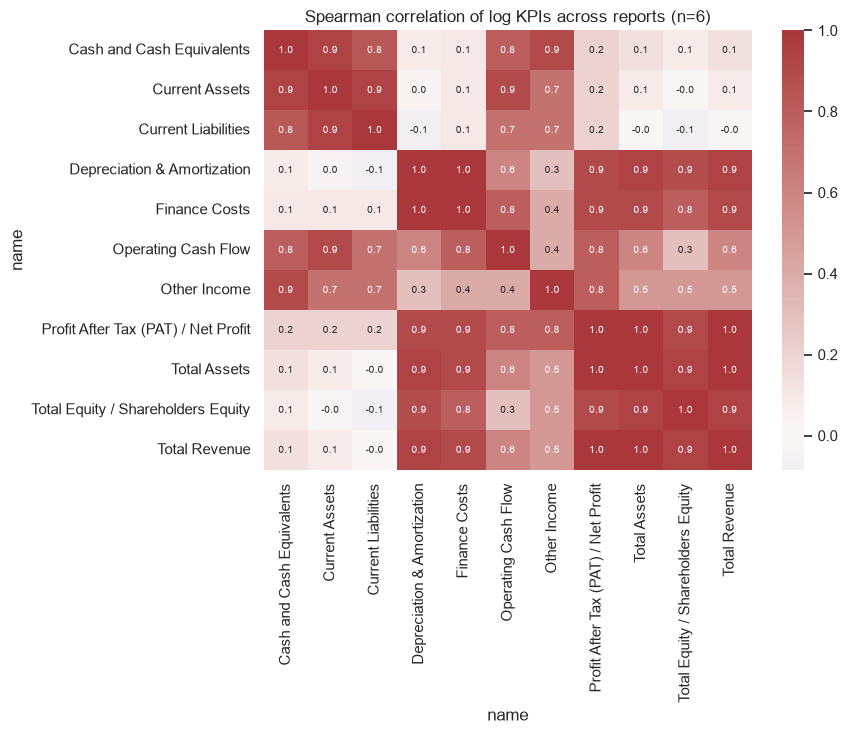

INSIGHT: Size-driven KPIs (assets, equity, revenue) are almost perfectly rank-correlated (ρ≈1.00 for assets~revenue): company size dominates. With only n=6 reports these correlations are descriptive, not inferential. That is another reason to use size-free ratios as model features.


In [20]:
wide = money.pivot_table(index="report", columns="name", values="value")
wide = wide.loc[:, wide.notna().sum() >= 5]
kcorr = np.log10(wide.abs().clip(lower=0.01)).corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(kcorr, cmap="vlag", center=0, annot=True, fmt=".1f", annot_kws={"size": 7}, ax=ax)
ax.set_title(f"Spearman correlation of log KPIs across reports (n={len(wide)})")
save("kpi_correlation")
EDA["kpi_corr"] = {"labels": kcorr.columns.tolist(), "matrix": kcorr.round(3).fillna(0).values.tolist()}
insight(f"Size-driven KPIs (assets, equity, revenue) are almost perfectly rank-correlated (ρ≈"
        f"{kcorr.loc['Total Assets', 'Total Revenue']:.2f} for assets~revenue): company size dominates. With only n={len(wide)} "
        f"reports these correlations are descriptive, not inferential. That is another reason to use size-free ratios as model features.")

## 7. Benford's law (forensic check)

In naturally occurring financial data, the leading digit d appears with probability
P(d) = log₁₀(1 + 1/d), so "1" leads about 30% of the time and "9" only about 4.6%.
Fabricated or manipulated figures often deviate from this. We test every number on the financial-statement
and notes pages:
* We exclude years (1990–2035), note references (< 10) and percentages.
* We compute a **χ² goodness-of-fit** test and **Nigrini's Mean Absolute Deviation (MAD)**.
  Nigrini's MAD thresholds: < 0.006 close conformity, < 0.012 acceptable, < 0.015 marginal, above that non-conformity.

**Which numbers count?** A first attempt took *every* integer of 10 or more, and digit **3** came out far
too often (about 21% vs 12.5% expected). The cause was dates ("31 March"), note numbers and line references.
Benford applies to *measured amounts*, so we keep only numbers written as amounts: comma-grouped
(1,23,456) or with decimals (1203.73). Nigrini recommends **at least 1,000 numbers** for a reliable test.

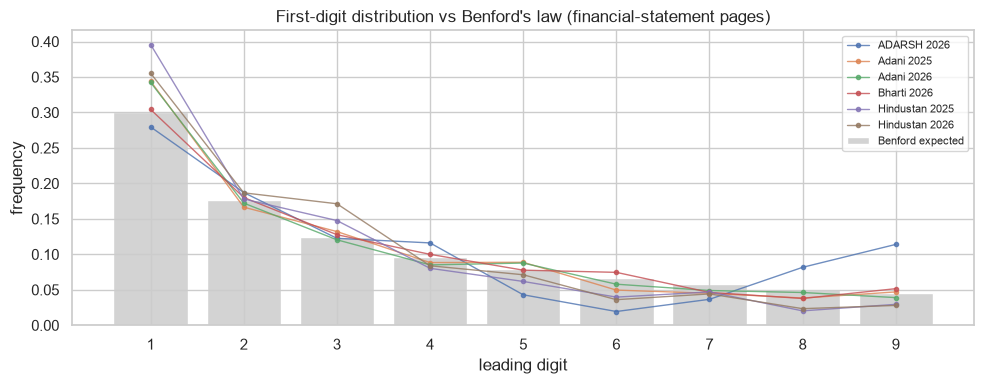

,report,n_numbers,chi2,p_value,MAD,verdict
0,ADARSH 2026,465,85.700000,3.44e-15,0.028700,insufficient sample
1,Adani 2025,6535,127.800000,7.94e-24,0.013600,marginal
2,Adani 2026,5302,65.400000,3.97e-11,0.011100,acceptable
3,Bharti 2026,4708,36.500000,1.40e-05,0.005900,close conformity
4,Hindustan 2025,1084,84.700000,5.42e-15,0.026500,non-conformity
5,Hindustan 2026,1109,77.200000,1.75e-13,0.024700,non-conformity


In [21]:
AMOUNT_RE = re.compile(r"(?<![\d.,])\(?(\d{1,3}(?:,\d{2,3})+(?:\.\d+)?|\d+\.\d+)\)?(?![\d,])")
FIN = {"balance_sheet", "profit_loss", "cash_flow", "equity_changes", "notes"}
MIN_N = 1000


def first_digits(text):
    out = []
    for m in AMOUNT_RE.finditer(text):
        s = m.group(1).replace(",", "")
        if float(s) < 10:
            continue
        out.append(int(s[0]))
    return out


benford = np.log10(1 + 1 / np.arange(1, 10))
rows, dist = [], {}
for report, g in pages[pages.label.isin(FIN)].groupby("report"):
    d = np.array([x for t in g.clean_text for x in first_digits(t)])
    obs = np.bincount(d, minlength=10)[1:]
    freq = obs / obs.sum()
    chi2, p = stats.chisquare(obs, benford * obs.sum())
    mad = np.abs(freq - benford).mean()
    verdict = ("insufficient sample" if obs.sum() < MIN_N else "close conformity" if mad < 0.006
               else "acceptable" if mad < 0.012 else "marginal" if mad < 0.015 else "non-conformity")
    rows.append({"report": report, "n_numbers": int(obs.sum()), "chi2": round(chi2, 1), "p_value": p,
                 "MAD": round(mad, 4), "verdict": verdict})
    dist[report] = freq.round(4).tolist()
bf = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 4))
for report, f in dist.items():
    ax.plot(range(1, 10), f, marker="o", ms=3, lw=1, alpha=.8, label=report)
ax.bar(range(1, 10), benford, color="lightgrey", label="Benford expected", zorder=0)
ax.set_xticks(range(1, 10))
ax.set_xlabel("leading digit")
ax.set_ylabel("frequency")
ax.set_title("First-digit distribution vs Benford's law (financial-statement pages)")
ax.legend(fontsize=8)
save("benford")
EDA["benford"] = {"expected": benford.round(4).tolist(), "observed": dist,
                  "tests": bf.assign(p_value=bf.p_value.map(lambda v: float(f"{v:.3g}"))).to_dict("records")}
bf.style.format({"p_value": "{:.2e}"})

In [22]:
flagged = bf[bf.verdict.isin(["marginal", "non-conformity"])].report.tolist()
insight(f"Reported amounts broadly follow Benford's law (digit 1 leads {np.mean([v[0] for v in dist.values()]):.1%} on "
        f"average vs {benford[0]:.1%} expected). MAD verdicts: " + ", ".join(f"{r.report}: {r.verdict} ({r.MAD})" for r in bf.itertuples())
        + (f". Deviating: {', '.join(flagged)}. A likely benign cause is figures in ₹ lakh with many repeated sub-totals, "
           "which we would investigate rather than conclude anything from" if flagged else "")
        + ". With thousands of numbers the χ² test rejects even tiny deviations (large-n sensitivity), so MAD is the "
        "practical criterion. Benford is a red-flag screen, not proof of manipulation.")

INSIGHT: Reported amounts broadly follow Benford's law (digit 1 leads 33.7% on average vs 30.1% expected). MAD verdicts: ADARSH 2026: insufficient sample (0.0287), Adani 2025: marginal (0.0136), Adani 2026: acceptable (0.0111), Bharti 2026: close conformity (0.0059), Hindustan 2025: non-conformity (0.0265), Hindustan 2026: non-conformity (0.0247). Deviating: Adani 2025, Hindustan 2025, Hindustan 2026. A likely benign cause is figures in ₹ lakh with many repeated sub-totals, which we would investigate rather than conclude anything from. With thousands of numbers the χ² test rejects even tiny deviations (large-n sensitivity), so MAD is the practical criterion. Benford is a red-flag screen, not proof of manipulation.


## 8. Export for the GUI

In [23]:
EDA["generated_from"] = {"pages": int(len(pages)), "reports": int(pages.report_id.nunique()), "kpi_rows": int(len(kp))}


def to_json_safe(o):
    """NaN/inf → None (strict JSON), numpy scalars → Python."""
    if isinstance(o, dict):
        return {str(k): to_json_safe(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_json_safe(v) for v in o]
    if isinstance(o, (np.floating, float)):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.integer):
        return int(o)
    return o


(REPORTS_DIR / "eda.json").write_text(
    json.dumps(to_json_safe(EDA), indent=1, ensure_ascii=False, allow_nan=False), encoding="utf-8")
print(f"wrote {REPORTS_DIR / 'eda.json'} with sections: {list(EDA)}")

wrote D:\annual-report-analyzer-main\ml\reports\eda.json with sections: ['corpus', 'insights', 'class_counts', 'feature_hist', 'feature_medians_by_label', 'kruskal', 'position_median', 'feature_corr', 'scope_chi2', 'top_terms', 'label_company_confound', 'tsne', 'silhouette', 'headline_kpis', 'ratios', 'yoy', 'kpi_corr', 'benford', 'generated_from']


## 9. Key findings

Each line below was printed by the analysis above:

In [24]:
for i, s in enumerate(EDA["insights"], 1):
    print(f"{i}. {s}\n")

1. 2,199 cleaned pages from 6 reports of 4 companies (1.20 M words). Report length ranges from 100 to 609 pages, so per-report section shares vary a lot.

2. Severe imbalance: the largest class ('notes', 825) is 92× the smallest ('equity_changes', 9). Primary statements (BS/P&L/CF/SoCE) are only 3.0% of pages, yet they hold the headline KPIs. So we use macro-F1 plus class weights, not accuracy.

3. Count features are right-skewed (n_words skew 1.11, n_numbers skew 4.19). log1p over-corrects n_words to -1.34 because of short divider pages; sqrt gives the most symmetric shape (0.28). Scale-sensitive models (LogReg/SVM) get power-transformed + standardised inputs (Yeo-Johnson in the pipeline); tree models need no transformation.

4. All features differ significantly across page types (Kruskal-Wallis p < 0.001). 'rel_position' separates best (ε²=0.463). Statement pages have a median digit_ratio of 0.14 vs 0.02 for narrative sections. The engineered features are informative.

5. Reports fol

**Implications for modelling (notebook 03)**
* **Target:** severe imbalance, so use class weights, compare SMOTE, and use macro-F1 as the selection metric.
* **Features:** structural features differ significantly by class (Kruskal–Wallis), and TF-IDF vocabulary is
  class-specific. Plan: combine both, log-transform the counts, and use L2 regularisation for redundant features.
* **Validation:** pages cluster by company template, so cross-validation must be **grouped by company** (GroupKFold).
* **KPIs:** use log or ratio scale, and size-free ratios as features for the financial-health classifier.
* **Forensics:** Benford MAD is cheap to compute and can be shown per filing as an integrity indicator.